# Этап 1. Формулы минимальной безопасной дистанции RSS

Код формул: `rssrl/rss.py`, проверки: `tests/test_rss.py`.
Здесь смотрим на формулы глазами: как d_min зависит от скоростей и что происходит в худшем случае, если передняя машина тормозит сильнее допущения.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from rssrl.rss import DEFAULT, d_min_longitudinal, d_min_lateral

FIG = Path('..') / 'results' / 'figures'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'lines.linewidth': 2})
print(DEFAULT)

RSSParams(rho=0.5, a_max_accel=3.0, a_min_brake=4.0, a_max_brake=5.0, a_lat_max_accel=0.2, a_lat_min_brake=0.8, mu=0.1)


## 1. Продольная дистанция (лемма 2)

$$d_{min} = \Big[v_r\rho + \tfrac12 a_{max,accel}\rho^2 + \frac{(v_r+\rho\, a_{max,accel})^2}{2a_{min,brake}} - \frac{v_f^2}{2a_{max,brake}}\Big]_+$$

$v_r$ — скорость задней машины (агента), $v_f$ — передней (лидера).

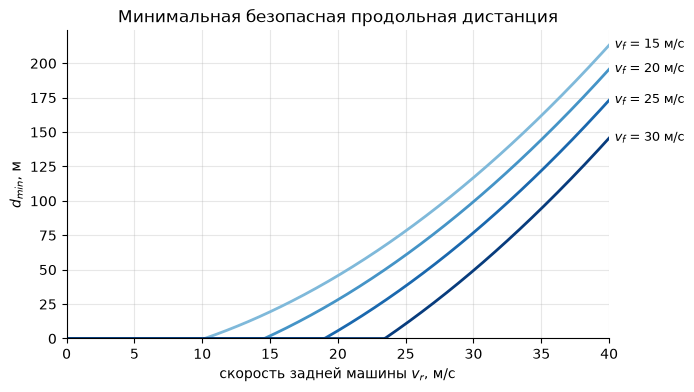

обе по 20 м/с (72 км/ч): d_min = 28.2 м, это 1.41 с хода
обе по 25 м/с (90 км/ч): d_min = 38.2 м, это 1.53 с хода
обе по 30 м/с (108 км/ч): d_min = 49.4 м, это 1.65 с хода


In [2]:
v_r = np.linspace(0, 40, 401)
fronts = [15, 20, 25, 30]
colors = plt.cm.Blues(np.linspace(0.45, 0.95, len(fronts)))
fig, ax = plt.subplots(figsize=(7, 4))
for v_f, c in zip(fronts, colors):
    d = [d_min_longitudinal(x, v_f) for x in v_r]
    ax.plot(v_r, d, color=c)
    ax.annotate(f'$v_f$ = {v_f} м/с', (40, d[-1]), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9)
ax.set_xlabel('скорость задней машины $v_r$, м/с')
ax.set_ylabel('$d_{min}$, м')
ax.set_title('Минимальная безопасная продольная дистанция')
ax.set_xlim(0, 40); ax.set_ylim(bottom=0)
fig.savefig(FIG / '01_dmin_longitudinal.png', dpi=150, bbox_inches='tight')
plt.show()

for v in [20, 25, 30]:
    d = d_min_longitudinal(v, v)
    print(f'обе по {v} м/с ({v*3.6:.0f} км/ч): d_min = {d:.1f} м, это {d/v:.2f} с хода')

При равных скоростях 25 м/с (90 км/ч) RSS требует около 38 м, примерно 1,5 с хода. Это совпадает с привычным правилом «держи 1,5–2 секунды».

## 2. Худший случай: что ломается при β > 1

Старт ровно с $d_{min}$, обе машины 25 м/с. Задняя ведет себя как в лемме (ρ секунд разгоняется, потом тормозит с $a_{min,brake}$ = 4 м/с²), а передняя тормозит с $\beta \cdot 5$ м/с². При β = 1 машины останавливаются впритык. При β > 1 зазор уходит ниже нуля, то есть происходит столкновение.

Это *худший* случай: задняя ведет себя как можно хуже. Настоящий фильтр начнет тормозить раньше и, возможно, сильнее, поэтому реальная частота столкновений — вопрос эксперимента, а не этой формулы.

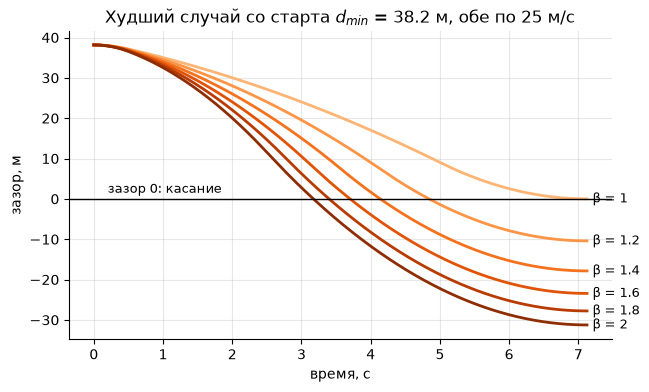

In [3]:
def worst_case_gap(gap0, v_rear, v_front, front_brake, p=DEFAULT, dt=1e-3):
    """Зазор во времени в худшем случае леммы 2 (машины не едут назад)."""
    t, x_r, x_f, vr, vf = 0.0, 0.0, gap0, v_rear, v_front
    ts, gaps = [0.0], [gap0]
    while vr > 0 or vf > 0 or t < p.rho:
        a_r = p.a_max_accel if t < p.rho else -p.a_min_brake
        nvr = max(0.0, vr + a_r * dt)
        nvf = max(0.0, vf - front_brake * dt)
        x_r += (vr + nvr) / 2 * dt
        x_f += (vf + nvf) / 2 * dt
        vr, vf, t = nvr, nvf, t + dt
        ts.append(t); gaps.append(x_f - x_r)
    return np.array(ts), np.array(gaps)

betas = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
v = 25.0
d0 = d_min_longitudinal(v, v)
colors = plt.cm.Oranges(np.linspace(0.35, 0.95, len(betas)))
fig, ax = plt.subplots(figsize=(7, 4))
for b, c in zip(betas, colors):
    t, g = worst_case_gap(d0, v, v, b * DEFAULT.a_max_brake)
    ax.plot(t, g, color=c)
    ax.annotate(f'β = {b:g}', (t[-1], g[-1]), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9)
ax.axhline(0, color='black', linewidth=1)
ax.text(0.2, 1.5, 'зазор 0: касание', fontsize=9)
ax.set_xlabel('время, с'); ax.set_ylabel('зазор, м')
ax.set_title(f'Худший случай со старта $d_{{min}}$ = {d0:.1f} м, обе по {v:.0f} м/с')
fig.savefig(FIG / '01_worst_case_beta.png', dpi=150, bbox_inches='tight')
plt.show()

Проверка формулой: машины в худшем случае не расходятся до остановки, поэтому итоговый зазор равен $d_{min}$ плюс путь передней минус путь задней. Нехватка при β > 1 равна разнице тормозных путей передней машины: $\frac{v_f^2}{2\cdot 5} - \frac{v_f^2}{2\cdot 5\beta}$.

In [4]:
print(' β   нехватка (симуляция), м   нехватка (формула), м')
for b in betas:
    _, g = worst_case_gap(d0, v, v, b * DEFAULT.a_max_brake)
    formula = v**2 / (2 * 5) - v**2 / (2 * 5 * b)
    print(f'{b:.1f}   {-g[-1]:10.2f}               {formula:10.2f}')

 β   нехватка (симуляция), м   нехватка (формула), м
1.0        -0.00                     0.00
1.2        10.42                    10.42
1.4        17.86                    17.86
1.6        23.44                    23.44
1.8        27.78                    27.78
2.0        31.25                    31.25


## 3. Поперечная дистанция (лемма 4)

Поперечные параметры: $a^{lat}_{max,accel}$ = 0,2 м/с², $a^{lat}_{min,brake}$ = 0,8 м/с², μ = 0,1 м (значения по умолчанию Intel ad-rss-lib, **сверить со статьей**). Скорость положительна, если машина 1 сдвигается к машине 2.

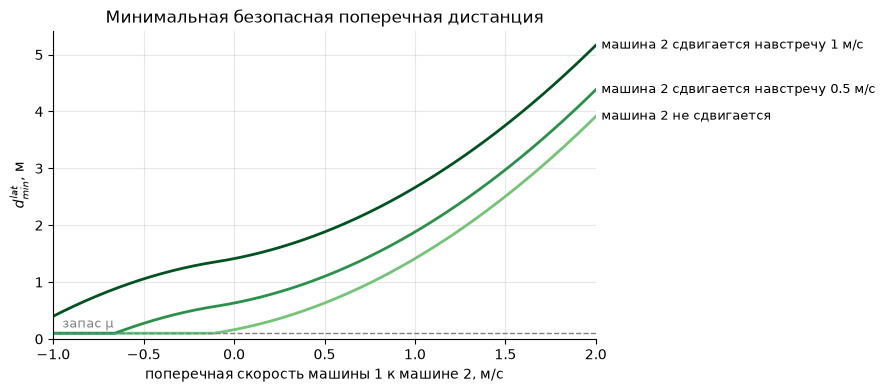

полоса 4 м, машина 2 м: зазор между машинами в соседних полосах ≈ 2 м
машина 1 сдвигается со скоростью 0.5 м/с: d_lat_min = 0.63 м
машина 1 сдвигается со скоростью 1.0 м/с: d_lat_min = 1.41 м
машина 1 сдвигается со скоростью 1.5 м/с: d_lat_min = 2.51 м


In [5]:
v1 = np.linspace(-1, 2, 301)
others = [0.0, -0.5, -1.0]
colors = plt.cm.Greens(np.linspace(0.5, 0.95, len(others)))
fig, ax = plt.subplots(figsize=(7, 4))
for v2, c in zip(others, colors):
    d = [d_min_lateral(x, v2) for x in v1]
    ax.plot(v1, d, color=c)
    label = 'не сдвигается' if v2 == 0 else f'сдвигается навстречу {-v2:g} м/с'
    ax.annotate(f'машина 2 {label}', (2, d[-1]), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9)
ax.axhline(DEFAULT.mu, color='gray', linewidth=1, linestyle='--')
ax.text(-0.95, DEFAULT.mu + 0.1, 'запас μ', fontsize=9, color='gray')
ax.set_xlabel('поперечная скорость машины 1 к машине 2, м/с')
ax.set_ylabel('$d^{lat}_{min}$, м')
ax.set_title('Минимальная безопасная поперечная дистанция')
ax.set_xlim(-1, 2); ax.set_ylim(bottom=0)
fig.savefig(FIG / '01_dmin_lateral.png', dpi=150, bbox_inches='tight')
plt.show()

print('полоса 4 м, машина 2 м: зазор между машинами в соседних полосах ≈ 2 м')
for v in [0.5, 1.0, 1.5]:
    print(f'машина 1 сдвигается со скоростью {v} м/с: d_lat_min = {d_min_lateral(v, 0):.2f} м')

При перестроении поперечная скорость составляет порядка 1–1,5 м/с, и $d^{lat}_{min}$ быстро превышает 2 м — зазор между машинами в соседних полосах. Значит, перестроение рядом с машиной в соседней полосе поперечная RSS будет запрещать, если ее нельзя обогнать или пропустить. Это проверим на этапе 4.